<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/LAB7_CSET343_E23CSEU0728.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSET343 - AI in Healthcare
## Lab Assignment 7: Deep Learning Grid Search (Pima Indians Diabetes)

**Objective:** Use the Grid Search capability of Scikit-learn to tune hyperparameters of a deep learning (Keras) model.

**Hyperparameters tuned:**
1. Batch size and training epochs
2. Learning rate
3. Network weight initialization
4. Activation functions
5. Dropout regularization
6. Number of neurons in the hidden layer

In [ ]:
!pip install -q tensorflow

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## Task 1: Data Acquisition and Loading

In [ ]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
           'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

# Use a local copy if one exists (e.g. diabetes.csv from Kaggle), otherwise download.
if os.path.exists('diabetes.csv'):
    df = pd.read_csv('diabetes.csv')
    df.columns = columns
else:
    df = pd.read_csv(url, header=None, names=columns)

print('Shape:', df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.info()
print()
print(df.describe().T)
print()
print('Class distribution:')
print(df['Outcome'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

                          count        mean         std     min       25%  \
Pregnancies               768.0    3.845052    3.369578   0.000   1.00000   
Glucose                   768.0  120.894531   31.972618   0.000  99.00000   
BloodPre

## Task 2: Data Preprocessing

In this dataset, a value of 0 in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` is physiologically impossible and represents a missing value. These are replaced with NaN, imputed with the median, and then the features are standardised.

In [ ]:
zero_as_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean = df.copy()
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)
print('Missing values per column:')
print(df_clean.isnull().sum())

X = df_clean.drop('Outcome', axis=1).values
y = df_clean['Outcome'].values

# Split first, then fit imputer/scaler on the training set only (avoids data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print('\nTrain:', X_train.shape, ' Test:', X_test.shape)

Missing values per column:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Train: (614, 8)  Test: (154, 8)


## Task 3: Deep Learning Grid Search

### 3.1 Keras model wrapped for Scikit-learn

`create_model` builds a Keras network whose hyperparameters are arguments. `KerasClassifierSK` is a small scikit-learn-compatible wrapper (it implements `fit`, `predict` and `get_params`/`set_params` through `BaseEstimator`), so `GridSearchCV` can tune the Keras model directly. Each hyperparameter is a constructor argument of the wrapper.

In [ ]:
def create_model(n_features, hidden_neurons=12, init_mode='glorot_uniform',
                 activation='relu', dropout_rate=0.0, learning_rate=0.001):
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(hidden_neurons, kernel_initializer=init_mode, activation=activation),
        layers.Dropout(dropout_rate),
        layers.Dense(1, kernel_initializer=init_mode, activation='sigmoid'),
    ])
    model.compile(loss='binary_crossentropy',
                  optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  metrics=['accuracy'])
    return model


class KerasClassifierSK(ClassifierMixin, BaseEstimator):
    """Minimal scikit-learn wrapper around a Keras model (works with GridSearchCV).
    Every tunable hyperparameter is an __init__ argument, so GridSearchCV can set it."""

    def __init__(self, hidden_neurons=12, init_mode='glorot_uniform', activation='relu',
                 dropout_rate=0.0, learning_rate=0.001, batch_size=16, epochs=50,
                 verbose=0, random_state=SEED):
        self.hidden_neurons = hidden_neurons
        self.init_mode = init_mode
        self.activation = activation
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.verbose = verbose
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype='float32')
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        keras.backend.clear_session()
        keras.utils.set_random_seed(self.random_state)
        self.model_ = create_model(X.shape[1], self.hidden_neurons, self.init_mode,
                                   self.activation, self.dropout_rate, self.learning_rate)
        self.model_.fit(X, y, batch_size=self.batch_size, epochs=self.epochs,
                        verbose=self.verbose)
        return self

    def predict_proba(self, X):
        p = self.model_.predict(np.asarray(X, dtype='float32'), verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def build_classifier():
    """Baseline classifier; grid search overrides whichever parameters are being tuned."""
    return KerasClassifierSK()


results_summary = {}   # best parameters from each experiment


def run_grid(param_grid, title, cv=3):
    grid = GridSearchCV(estimator=build_classifier(), param_grid=param_grid,
                        cv=cv, scoring='accuracy', n_jobs=1)
    grid_result = grid.fit(X_train, y_train)

    print(f'=== {title} ===')
    print(f'Best: {grid_result.best_score_:.4f} using {grid_result.best_params_}\n')
    means = grid_result.cv_results_['mean_test_score']
    stds = grid_result.cv_results_['std_test_score']
    params = grid_result.cv_results_['params']
    for mean, std, param in zip(means, stds, params):
        print(f'{mean:.4f} ({std:.4f}) with: {param}')

    results_summary[title] = {
        'best_score': grid_result.best_score_,
        'best_params': grid_result.best_params_,
    }
    return grid_result

### 3.2 Tune batch size and training epochs

In [ ]:
param_grid = {
    'batch_size': [10, 20, 40, 60, 80, 100],
    'epochs': [10, 50, 100],
}
res_batch_epochs = run_grid(param_grid, 'Batch size & epochs')

=== Batch size & epochs ===
Best: 0.7834 using {'batch_size': 60, 'epochs': 100}

0.7736 (0.0090) with: {'batch_size': 10, 'epochs': 10}
0.7785 (0.0201) with: {'batch_size': 10, 'epochs': 50}
0.7753 (0.0195) with: {'batch_size': 10, 'epochs': 100}
0.7557 (0.0135) with: {'batch_size': 20, 'epochs': 10}
0.7785 (0.0176) with: {'batch_size': 20, 'epochs': 50}
0.7834 (0.0201) with: {'batch_size': 20, 'epochs': 100}
0.7183 (0.0156) with: {'batch_size': 40, 'epochs': 10}
0.7671 (0.0161) with: {'batch_size': 40, 'epochs': 50}
0.7802 (0.0275) with: {'batch_size': 40, 'epochs': 100}
0.6694 (0.0148) with: {'batch_size': 60, 'epochs': 10}
0.7801 (0.0064) with: {'batch_size': 60, 'epochs': 50}
0.7834 (0.0216) with: {'batch_size': 60, 'epochs': 100}
0.6482 (0.0073) with: {'batch_size': 80, 'epochs': 10}
0.7541 (0.0175) with: {'batch_size': 80, 'epochs': 50}
0.7688 (0.0215) with: {'batch_size': 80, 'epochs': 100}
0.6352 (0.0068) with: {'batch_size': 100, 'epochs': 10}
0.7509 (0.0178) with: {'batch_si

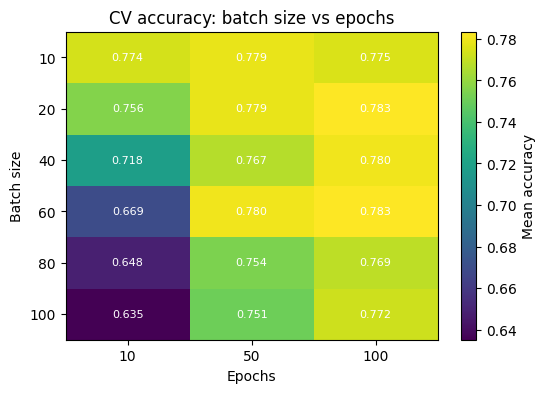

In [ ]:
# Visualise: heatmap of mean CV accuracy for batch size vs epochs
r = pd.DataFrame(res_batch_epochs.cv_results_)
pivot = r.pivot(index='param_batch_size', columns='param_epochs', values='mean_test_score')
plt.figure(figsize=(6, 4))
plt.imshow(pivot.values, cmap='viridis', aspect='auto')
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel('Epochs'); plt.ylabel('Batch size')
plt.title('CV accuracy: batch size vs epochs')
plt.colorbar(label='Mean accuracy')
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        plt.text(j, i, f'{pivot.values[i, j]:.3f}', ha='center', va='center', color='white', fontsize=8)
plt.show()

### 3.3 Tune the learning rate

The Adam optimizer's learning rate is tuned via the `learning_rate` parameter.

In [ ]:
param_grid = {
    'learning_rate': [0.0001, 0.001, 0.01, 0.05, 0.1, 0.2],
}
res_lr = run_grid(param_grid, 'Learning rate')

=== Learning rate ===
Best: 0.7802 using {'learning_rate': 0.001}

0.7264 (0.0135) with: {'learning_rate': 0.0001}
0.7802 (0.0218) with: {'learning_rate': 0.001}
0.7427 (0.0297) with: {'learning_rate': 0.01}
0.7378 (0.0260) with: {'learning_rate': 0.05}
0.7525 (0.0239) with: {'learning_rate': 0.1}
0.7232 (0.0254) with: {'learning_rate': 0.2}


### 3.4 Tune network weight initialization

In [ ]:
param_grid = {
    'init_mode': ['random_uniform', 'random_normal', 'zeros', 'lecun_uniform',
                         'glorot_normal', 'glorot_uniform', 'he_normal', 'he_uniform'],
}
res_init = run_grid(param_grid, 'Weight initialization')

=== Weight initialization ===
Best: 0.7883 using {'init_mode': 'he_normal'}

0.7802 (0.0178) with: {'init_mode': 'random_uniform'}
0.7769 (0.0236) with: {'init_mode': 'random_normal'}
0.6515 (0.0020) with: {'init_mode': 'zeros'}
0.7785 (0.0201) with: {'init_mode': 'lecun_uniform'}
0.7834 (0.0240) with: {'init_mode': 'glorot_normal'}
0.7802 (0.0218) with: {'init_mode': 'glorot_uniform'}
0.7883 (0.0240) with: {'init_mode': 'he_normal'}
0.7737 (0.0216) with: {'init_mode': 'he_uniform'}


### 3.5 Tune activation functions

The activation of the hidden layer is tuned. The output layer remains sigmoid for binary classification.

In [ ]:
param_grid = {
    'activation': ['softmax', 'softplus', 'softsign', 'relu',
                          'tanh', 'sigmoid', 'hard_sigmoid', 'linear'],
}
res_act = run_grid(param_grid, 'Activation function')

=== Activation function ===
Best: 0.7850 using {'activation': 'softsign'}

0.7818 (0.0056) with: {'activation': 'softmax'}
0.7802 (0.0115) with: {'activation': 'softplus'}
0.7850 (0.0133) with: {'activation': 'softsign'}
0.7802 (0.0218) with: {'activation': 'relu'}
0.7818 (0.0192) with: {'activation': 'tanh'}
0.7752 (0.0040) with: {'activation': 'sigmoid'}
0.7753 (0.0064) with: {'activation': 'hard_sigmoid'}
0.7802 (0.0206) with: {'activation': 'linear'}


### 3.6 Tune dropout regularization

In [ ]:
param_grid = {
    'dropout_rate': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
}
res_dropout = run_grid(param_grid, 'Dropout rate')

=== Dropout rate ===
Best: 0.7899 using {'dropout_rate': 0.1}

0.7802 (0.0218) with: {'dropout_rate': 0.0}
0.7899 (0.0076) with: {'dropout_rate': 0.1}
0.7867 (0.0087) with: {'dropout_rate': 0.2}
0.7802 (0.0155) with: {'dropout_rate': 0.3}
0.7785 (0.0126) with: {'dropout_rate': 0.4}
0.7801 (0.0145) with: {'dropout_rate': 0.5}
0.7866 (0.0131) with: {'dropout_rate': 0.6}


### 3.7 Tune the number of neurons in the hidden layer

In [ ]:
param_grid = {
    'hidden_neurons': [1, 5, 10, 15, 20, 25, 30, 50, 64],
}
res_neurons = run_grid(param_grid, 'Hidden neurons')

=== Hidden neurons ===
Best: 0.7899 using {'hidden_neurons': 20}

0.7541 (0.0214) with: {'hidden_neurons': 1}
0.7671 (0.0135) with: {'hidden_neurons': 5}
0.7801 (0.0064) with: {'hidden_neurons': 10}
0.7769 (0.0261) with: {'hidden_neurons': 15}
0.7899 (0.0134) with: {'hidden_neurons': 20}
0.7753 (0.0258) with: {'hidden_neurons': 25}
0.7769 (0.0175) with: {'hidden_neurons': 30}
0.7818 (0.0192) with: {'hidden_neurons': 50}
0.7737 (0.0236) with: {'hidden_neurons': 64}


## 4. Summary of tuning results

In [ ]:
summary_df = pd.DataFrame([
    {'Hyperparameter': k, 'Best CV accuracy': round(v['best_score'], 4), 'Best value(s)': v['best_params']}
    for k, v in results_summary.items()
])
summary_df

,Hyperparameter,Best CV accuracy,Best value(s)
0,Batch size & epochs,0.7834,"{'batch_size': 60, 'epochs': 100}"
1,Learning rate,0.7802,{'learning_rate': 0.001}
2,Weight initialization,0.7883,{'init_mode': 'he_normal'}
3,Activation function,0.7850,{'activation': 'softsign'}
4,Dropout rate,0.7899,{'dropout_rate': 0.1}
5,Hidden neurons,0.7899,{'hidden_neurons': 20}


## 5. Final model with the tuned hyperparameters

Each hyperparameter was tuned independently (one-at-a-time, the standard approach for this lab as it keeps the search cost low). The best values are now combined and the final model is evaluated on the held-out test set.

In [ ]:
best = {}
for v in results_summary.values():
    best.update(v['best_params'])
print('Combined best parameters:', best)

final_clf = build_classifier()
final_clf.set_params(**best)
final_clf.fit(X_train, y_train)

y_pred = final_clf.predict(X_test)
print(f'\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}\n')
print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))

Combined best parameters: {'batch_size': 60, 'epochs': 100, 'learning_rate': 0.001, 'init_mode': 'he_normal', 'activation': 'softsign', 'dropout_rate': 0.1, 'hidden_neurons': 20}

Test accuracy: 0.7143

              precision    recall  f1-score   support

 No diabetes       0.77      0.79      0.78       100
    Diabetes       0.60      0.57      0.58        54

    accuracy                           0.71       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.71      0.71       154

Confusion matrix:
[[79 21]
 [23 31]]


## 6. Observations

- Write your observations here: which batch size / epochs combination performed best, how sensitive the model was to the learning rate, which initialisers and activations helped or hurt, whether dropout improved generalisation, and how the number of hidden neurons affected accuracy.
- Because the dataset is small (768 rows), CV scores vary by a point or two between runs, so small differences between settings may not be significant.